# Luthera Family Plots

The family data has changed to include the n, s and g variables to try and plot the Secular Resonances.


In [2]:
import pandas as pd
import numpy as np
import h5py as h5
from pathlib import Path
import datetime as datetime

import matplotlib.pyplot as plt
import matplotlib as mpl

np.set_printoptions(precision=2)

In [3]:
project_dir = Path('../../luthera_ast/')
plot_dir = project_dir / 'plots'

path = project_dir / 'luther_proper.h5'
luth_fam = pd.read_hdf(path)

# 2 Body mean motion resonance atlas
path = project_dir / 'MMR_atlas.h5'
mmr_atlas = pd.read_hdf(path)

In [4]:
luth_fam['irad'] = np.arcsin(luth_fam['sineI_P'])
luth_fam['ideg'] = np.degrees(luth_fam['irad'])

p_v = 0.0387

luth_fam['diam']= ((1329 * 10**(-luth_fam['abs_mag']/5)) * (p_v ** (-0.5)))

luth_fam.describe()

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam
count,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.0,878.000000,878.000000,878.000000
mean,16.175513,3.208147,0.123992,0.323863,62.636725,163.961034,-74.485114,259.071526,-10.0,0.329816,18.897053,4.478502
std,0.987079,0.014558,0.008572,0.005743,0.426461,57.980031,1.524164,752.086762,0.0,0.006072,0.347883,3.757710
min,9.480000,3.172780,0.106420,0.312013,61.765176,85.871008,-79.056097,5.500000,-10.0,0.317312,18.180615,1.752546
25%,15.620000,3.196843,0.117742,0.320017,62.306345,118.604830,-75.573336,29.200000,-10.0,0.325747,18.663932,2.829238
50%,16.390000,3.207515,0.123102,0.323137,62.653273,146.082211,-74.454953,82.950000,-10.0,0.329043,18.852771,3.561800
75%,16.890000,3.219394,0.129977,0.327705,62.966784,194.958434,-73.310560,250.000000,-10.0,0.333874,19.129562,5.077729
max,17.930000,3.238196,0.144674,0.340954,63.701778,361.322776,-71.181669,10000.000000,-10.0,0.347932,19.935032,85.836005


In [34]:
mmr_atlas[(mmr_atlas.sma >= 3.0) & (mmr_atlas.sma <= 3.45) & (mmr_atlas.strength >= 1e-13)]

,planet,ratio1,ratio2,sma,ecc,inc,w,ln,R,strength,width,sigma,periods
1022,J,9,4,3.02897,0.15,8.0,60.0,0.0,6.002700e-08,2.793100e-12,0.002366,214 999 999 999,4501.0
1028,J,11,5,3.07469,0.15,8.0,60.0,0.0,6.024600e-08,5.419000e-13,0.001066,15 999 999 999,8297.0
1029,J,13,6,3.10614,0.15,8.0,60.0,0.0,6.040000e-08,1.090800e-13,0.000485,177 999 999 999,15570.0
1037,Ma,1,3,3.16938,0.15,8.0,60.0,0.0,3.215700e-11,7.179500e-13,0.001240,299 999 999 999,11360.0
1040,S,5,1,3.26743,0.15,8.0,60.0,0.0,9.131700e-09,3.628800e-13,0.000955,263 999 999 999,53870.0
1041,J,2,1,3.27640,0.15,8.0,60.0,0.0,6.129500e-08,8.053500e-09,0.150420,5 999 999 999,398.7
1051,J,17,9,3.40365,0.15,8.0,60.0,0.0,6.203500e-08,1.169600e-13,0.000577,0 999 999 999,10980.0
1052,J,15,8,3.42044,0.15,8.0,60.0,0.0,6.213800e-08,5.587900e-13,0.001270,197 999 999 999,5681.0
1055,J,13,7,3.44233,0.15,8.0,60.0,0.0,6.227300e-08,2.764700e-12,0.002852,36 999 999 999,2938.0


In [26]:
# MMR values in AU
mmrs_3b_luthera = {'3J:2S:1':[3.079,3.083,0.94], 
                   '6J:3S:1':[3.141,3.145,0.94],
                   '8J:3S:1':[3.17,3.175,0.94],
                   '5J:2S:2':[3.174,3.180,0.94], 
                   '5J:3S:3':[3.207,3.205,0.94]}

def plot_2b_mmr(ax, sma_range, line_min, line_max, min_strength=1e-13):
    plt_2b_mmr = mmr_atlas[(mmr_atlas.sma >= sma_range[0]) & (mmr_atlas.sma <= sma_range[1]) & (mmr_atlas.strength > min_strength)]    

    for _, mmr in plt_2b_mmr.iterrows():
        label = f"{mmr.ratio1}{mmr.planet[0]}:{mmr.ratio2}"
        if mmr.sma-mmr.width > sma_range[0]:
            ax.vlines(mmr.sma-mmr.width, line_min, line_max, linestyles='dashed', alpha=0.25)
        ax.vlines(mmr.sma, line_min, line_max, linestyles='dashed')
        if mmr.sma+mmr.width < sma_range[1]:
            ax.vlines(mmr.sma+mmr.width, line_min, line_max, linestyles='dashed', alpha=0.25)
        ax.text(mmr.sma*1.0002, line_max*1.0008, label)


def plot_3b_mmr(ax, sma_range, line_min, line_max):
    for mmr_nme, sma in mmrs_3b_luthera.items():
        if sma[0] < sma_range[0] or sma[0] > sma_range[1]:
            continue
        ax.vlines(sma[0], line_min, line_max, linestyles='dashed')
        ax.text(sma[1], line_max * sma[2], mmr_nme, rotation=90)


# add the MMR lines in a plot with an semi-major axis (a) x axis.
def plot_mmrs(ax, sma_range, line_min, line_max, min_strength=1e-13):
    plot_2b_mmr(ax, sma_range, line_min, line_max, min_strength)
    plot_3b_mmr(ax, sma_range, line_min, line_max)

e_ax = 1
e_pe = 0.9833
e_ap = 1.0167
e_ecc = 0.0167

mars_sma = 1.524
mars_ecc = 0.0167
mars_a = 1.666
mars_p = 1.381

jupiter_sma = 5.2038
jupiter_ecc = 0.0489
jupiter_a = 5.367
jupiter_p = 5.035
j21_ax = 3.279

# Planetary mean motions deg/yr
jupiter_n5 = 360/(4333/365.25) 
saturn_n6 = 360/(10759/365.25)
uranus_n7 = 360/(30687/365.25)
neptune_n8 = 360/(60190/365.25)

# Planetary perihelion precession ''/yr
jupiter_g5 = 4.527
saturn_g6 = 28.243
uranus_g7 = 3.093
neptune_g8 = 0.673

# Planetary node precession ''/yr
saturn_s6 = -26.345
uranus_s7 = -2.996
neptune_s8 = -0.693

# Find the eccentricities that cause a body to cross the orbit of mars or jupiter
a_range = np.linspace(1.8, 3.9, 1000)

# We want the aphelion for jupiter_p for an range of a
#jupiter_p = a(1+e)
jupiter_crossing_e = (jupiter_p/a_range)-1
jupiter_q = np.vstack([a_range, jupiter_crossing_e])

mars_crossing_e = 1-(a_range/mars_a)
mars_Q = np.vstack([a_range, mars_crossing_e])

plot_values = np.where((jupiter_q[0,:]>=3.17) & (jupiter_q[0,:]<=3.24))[0]

def plot_js_crossing_e(ax,x_min, x_max):
    plot_values = np.where((jupiter_q[0,:]>=x_min) & (jupiter_q[0,:]<=x_max))[0]
    ax.plot(mars_Q[:,np.array(plot_values)][0],mars_Q[:,np.array(plot_values)][1])
    ax.plot(jupiter_q[:,np.array(plot_values)][0],jupiter_q[:,np.array(plot_values)][1])


def get_ap_pe(sma, ecc):
    pe = sma*(1-ecc)
    ap = sma*(1+ecc)
    return pe, ap
    

## Plot a asteroid family context scatter 
this plot includes: 
* Jupiter and Mars crossing lines
* MMR resonance lines
* Secular resonance lines


In [7]:
all_proper = pd.read_hdf(project_dir / 'afp_proper_elements.h5')

In [8]:
#define the neighbourhood
luth_a_min = luth_fam.a_P.min()
luth_a_max = luth_fam.a_P.max()

luth_i_min = luth_fam.sineI_P.min()
luth_i_max = luth_fam.sineI_P.max()

range_ratio = 2.5
a_range = (luth_a_max-luth_a_min)
neighbr_a_min = 3.0 #luth_a_min - (a_range*range_ratio)
neighbr_a_max = 3.45 #luth_a_max + (a_range*range_ratio)

i_range = (luth_i_max-luth_i_min)
neighbr_i_min = luth_i_min - (i_range*range_ratio)
neighbr_i_max = luth_i_max + (i_range*range_ratio)

neighbr_asteroids = all_proper[(all_proper.a_P>=neighbr_a_min) & (all_proper.a_P<=neighbr_a_max) &
                                (all_proper.sineI_P>=neighbr_i_min) & (all_proper.sineI_P<=neighbr_i_max)]
neighbr_asteroids.describe()

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time
count,66293.000000,66293.000000,66293.000000,66293.000000,66293.000000,66293.000000,66293.000000,66293.000000,66293.0
mean,16.295650,3.134314,0.158051,0.293167,64.903815,90.845231,-82.548145,1138.106263,-10.0
std,1.157924,0.060499,0.072577,0.038810,1.856100,57.359570,17.174801,8053.192422,0.0
min,6.180000,3.000008,0.000969,0.239663,56.171621,-695.267876,-269.982536,0.100000,-10.0
25%,15.720000,3.092251,0.097592,0.267641,63.640657,61.346503,-90.720607,12.000000,-10.0
50%,16.540000,3.134456,0.166879,0.285234,64.854916,75.047265,-78.787544,47.400000,-10.0
75%,17.090000,3.174137,0.208493,0.306804,66.186659,105.509435,-70.433910,270.300000,-10.0
max,19.360000,3.449340,0.463888,0.413267,69.266750,666.102477,-10.022626,100000.000000,-10.0


In [9]:
def calc_crossing_e(sma, ecc, pe_min, ap_max):
    pe, ap = get_ap_pe(sma, ecc) 
    ap_axes = np.linspace(pe_min, sma, 100)
    pe_eccs = (sma/ap_axes)-1
    pe_vals = np.vstack([ap_axes,pe_eccs])
    
    pe_axes = np.linspace(sma, ap_max, 100)
    ap_eccs = 1-(sma/pe_axes)
    ap_vals = np.vstack([pe_axes,ap_eccs])
    return pe_vals, ap_vals

def plot_crossing_e(ax, sma, ecc, pe_min, ap_max, labels=[]):
    pe_vals, ap_vals = calc_crossing_e(sma, ecc, pe_min, ap_max)
    if not any(pe_vals[1]<0):
        ax.plot(pe_vals[0], pe_vals[1], ls='-.', c='gray')
        if labels:
            ax.text(labels[0], labels[1], f'$q_{labels[2]}$')
    if not any(ap_vals[1]<0):
        if labels:
            ax.text(labels[0], labels[1], f'$Q_{labels[2]}$')
        ax.plot(ap_vals[0], ap_vals[1], ls='-.', c='gray')
    

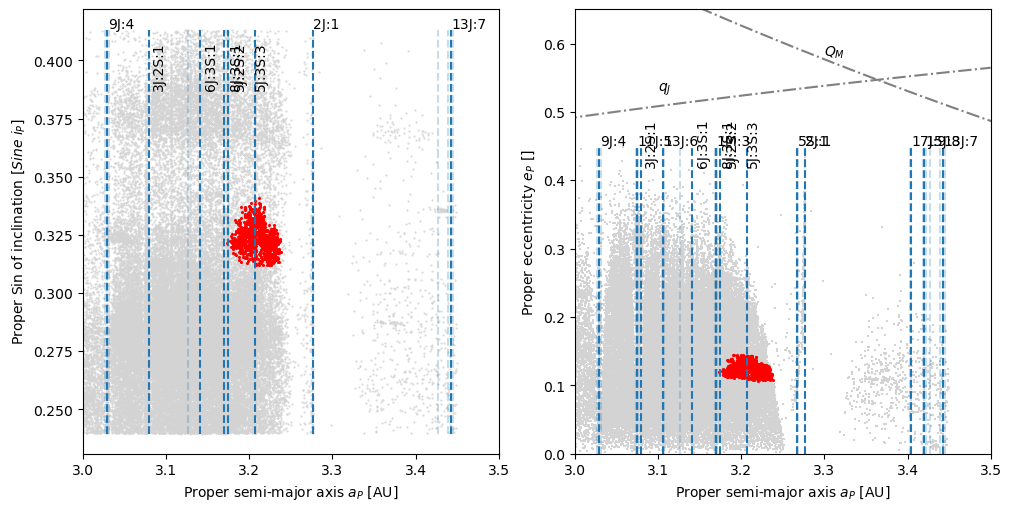

In [35]:
sma_range = (neighbr_a_min, neighbr_a_max)

fig = plt.figure(figsize=(10, 5), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])
ax1.set_xlim(3.0, 3.5)

ax1.scatter(data=neighbr_asteroids, x='a_P',y='sineI_P', marker=".", c='lightgrey', s=1)
ax1.scatter(data=luth_fam, x='a_P',y='sineI_P', edgecolors='red', marker="*", c='red', s=2)

luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','sineI_P']].values

ax1.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)

ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper Sin of inclination [$Sine ~i_P$]")

plot_mmrs(ax1, sma_range, neighbr_i_min, neighbr_i_max, min_strength=1e-12)

ax2 = fig.add_subplot(spec[0, 1])
ax2.set_xlim(3.0, 3.5)
ax2.set_ylim(0.0, 0.65)
ax2.scatter(data=neighbr_asteroids, x='a_P',y='e_P', marker="+", c='lightgrey', s=1)
ax2.scatter(data=luth_fam, x='a_P',y='e_P', edgecolors='red', marker="*", c='red', s=2)

luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','e_P']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper eccentricity $e_P$ []")
plot_mmrs(ax2, sma_range, 0.0, 0.45, min_strength=1e-13)

labels=[3.1,0.53,r'J']
plot_crossing_e(ax2, jupiter_sma, jupiter_ecc, 3.0, 3.5, labels)
labels=[3.3,0.582,r'M']
plot_crossing_e(ax2, mars_sma, mars_ecc, 3.0, 3.5, labels)

plt.savefig(plot_dir / "neighbour_aei.png", dpi=300)
plt.show()


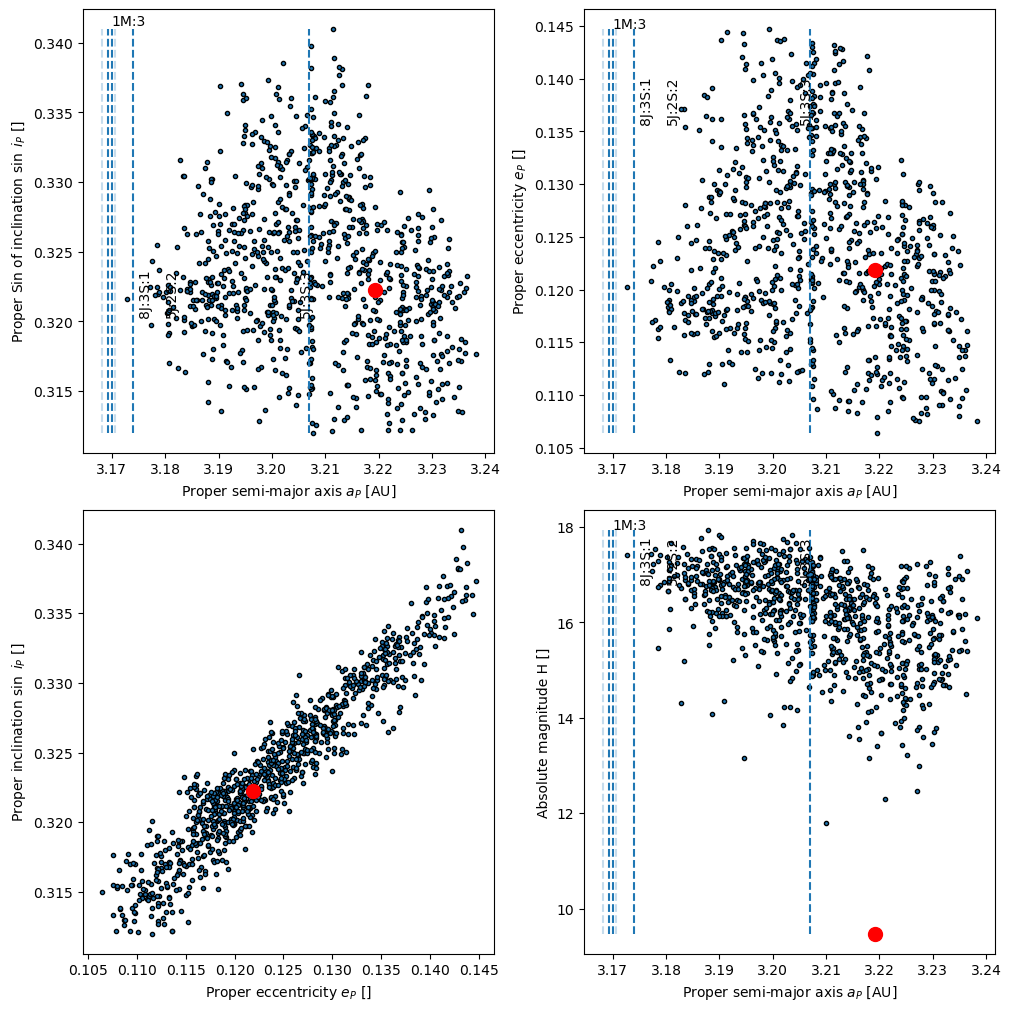

In [28]:
sma_range = (3.15, 3.26)

fig = plt.figure(figsize=(10, 10), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=2)

ax1 = fig.add_subplot(spec[0, 0])
ax1.scatter(data=luth_fam, x='a_P',y='sineI_P', edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','sineI_P']].values
ax1.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper Sin of inclination $\sin ~i_P$ []")
plot_mmrs(ax1, sma_range, luth_fam.sineI_P.min(), luth_fam.sineI_P.max())

ax2 = fig.add_subplot(spec[0, 1])
ax2.scatter(data=luth_fam, x='a_P',y='e_P', edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','e_P']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper eccentricity $e_P$ []")
plot_mmrs(ax2, sma_range, luth_fam.e_P.min(), luth_fam.e_P.max())

ax3 = fig.add_subplot(spec[1, 0])
plt.scatter(data=luth_fam, x='e_P',y='sineI_P' , edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['e_P','sineI_P']].values
ax3.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax3.set_xlabel("Proper eccentricity $e_P$ []")
ax3.set_ylabel("Proper inclination $\sin ~i_P$ []")

ax4 = fig.add_subplot(spec[1, 1])
ax4.scatter(data=luth_fam, x='a_P',y='abs_mag' , edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','abs_mag']].values
ax4.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax4.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax4.set_ylabel("Absolute magnitude H []")
plot_mmrs(ax4, sma_range, luth_fam.abs_mag.min(), luth_fam.abs_mag.max())

plt.savefig(f"../../dissertation/luthera_prp_ieM.png", dpi=300)
plt.show()


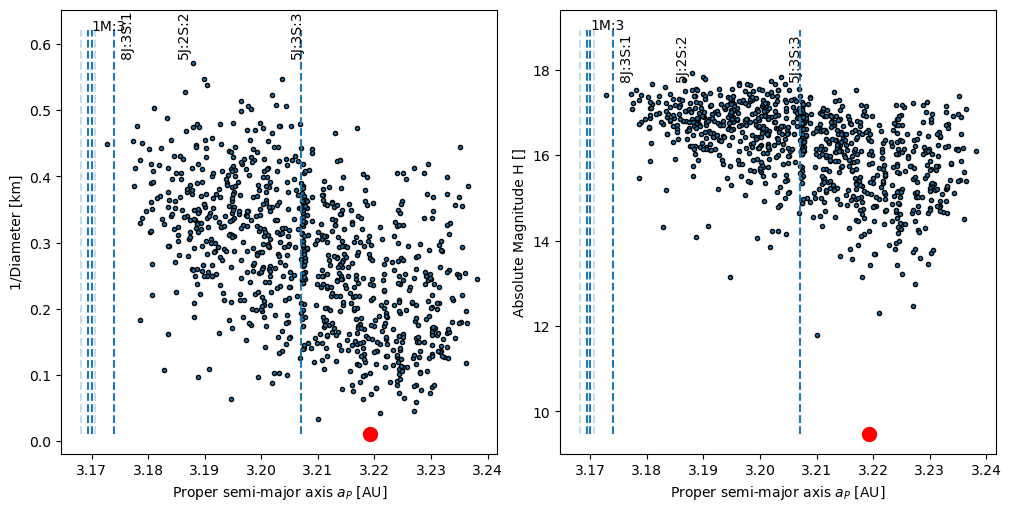

In [15]:
fig = plt.figure(figsize=(10, 5), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])

over_D = 1/luth_fam.diam

ax1.scatter(x=luth_fam.a_P,y=over_D, edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','diam']].values
ax1.plot(luth_ie[0][0],1/luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("1/Diameter [km]")
plot_mmrs(ax1, sma_range, over_D.min(), over_D.max()+0.05)

ax2 = fig.add_subplot(spec[0, 1])
ax2.scatter(x=luth_fam.a_P,y=luth_fam.abs_mag , edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','abs_mag']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Absolute Magnitude H []")
plot_mmrs(ax2, sma_range, luth_fam.abs_mag.min(), luth_fam.abs_mag.max()+1)

plt.savefig(f"../../dissertation/luthera_prp_DM.png", dpi=300)
plt.show()


In [12]:
brights = luth_fam[luth_fam['abs_mag']<13]

brights

,ast_name,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam
0,1303,9.48,3.219248,0.121842,0.322276,62.310603,193.693422,-75.178531,500.0,-10,0.328133,18.800642,85.836005
1,11911,11.80,3.210027,0.132169,0.330567,62.579772,151.725694,-75.054158,48.8,-10,0.336904,19.303169,29.489642
3,17840,12.46,3.227073,0.122213,0.322861,62.084582,243.861008,-76.365994,123.5,-10,0.328751,18.836035,21.760531
5,33292,12.99,3.227360,0.129485,0.326713,62.075202,246.598756,-77.825804,46.5,-10,0.332824,19.069401,17.047845
15,65871,12.31,3.221049,0.122196,0.322120,62.258472,203.766346,-75.515723,77.5,-10,0.327968,18.791194,23.316830


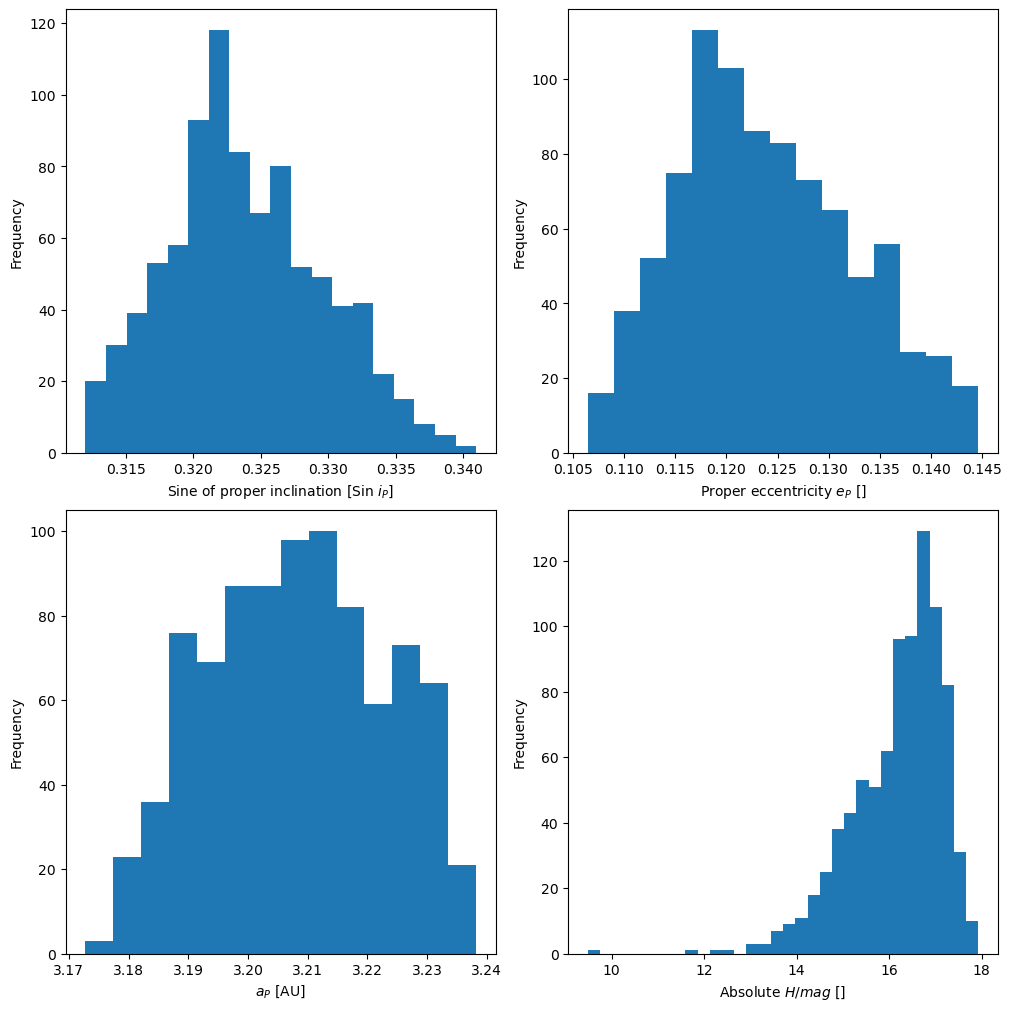

In [13]:
y_label = "Frequency"

fig = plt.figure(figsize=(10, 10), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=2)

ax1 = fig.add_subplot(spec[0, 0])
ax1.hist(data=luth_fam, x='sineI_P', bins='auto')
ax1.set_ylabel(y_label)
ax1.set_xlabel("Sine of proper inclination [Sin $i_P$]")

ax2 = fig.add_subplot(spec[0, 1])
ax2.hist(data=luth_fam, x='e_P', bins='auto')
ax2.set_ylabel(y_label)
ax2.set_xlabel("Proper eccentricity $e_P$ []")

ax3 = fig.add_subplot(spec[1, 0])
ax3.hist(data=luth_fam, x='a_P', bins='auto')
ax3.set_ylabel(y_label)
ax3.set_xlabel("$a_P$ [AU]")

ax4 = fig.add_subplot(spec[1, 1])
ax4.hist(data=luth_fam, x='abs_mag' , bins='auto')
ax4.set_ylabel(y_label)
ax4.set_xlabel("Absolute $H / mag$ []")

plt.savefig(f"../../dissertation/luthera_prp_hist.png", dpi=300)

plt.show()

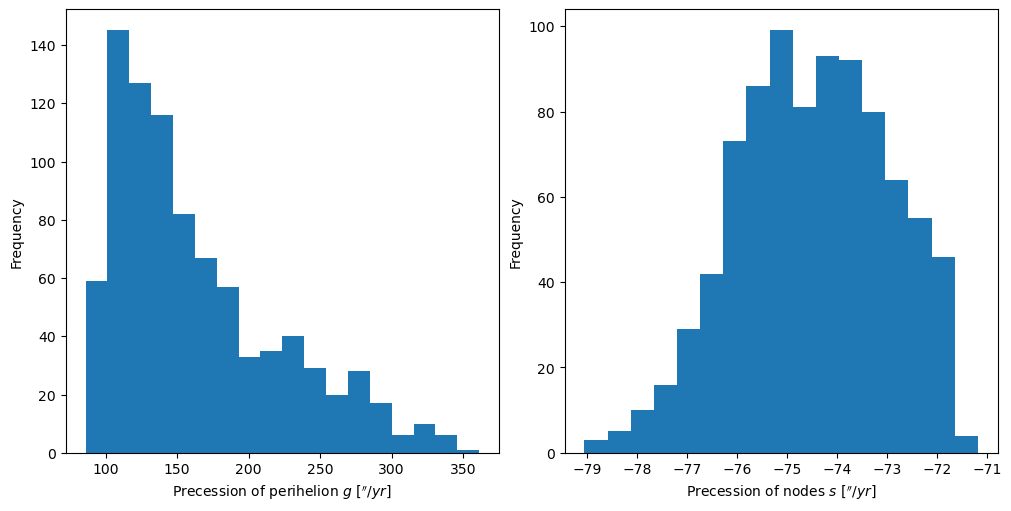

In [14]:
fig = plt.figure(figsize=(10, 5), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])

ax1.hist(data=luth_fam, x='g', bins='auto')
ax1.set_ylabel("Frequency")
ax1.set_xlabel("Precession of perihelion $g$ [$''/yr$]")

ax2 = fig.add_subplot(spec[0, 1])

ax2.hist(data=luth_fam, x='s', bins='auto')
ax2.set_ylabel("Frequency")
ax2.set_xlabel("Precession of nodes $s$ [$''/yr$]")

plt.savefig(f"../../dissertation/luthera_prp_gs.png", dpi=300)
plt.show()

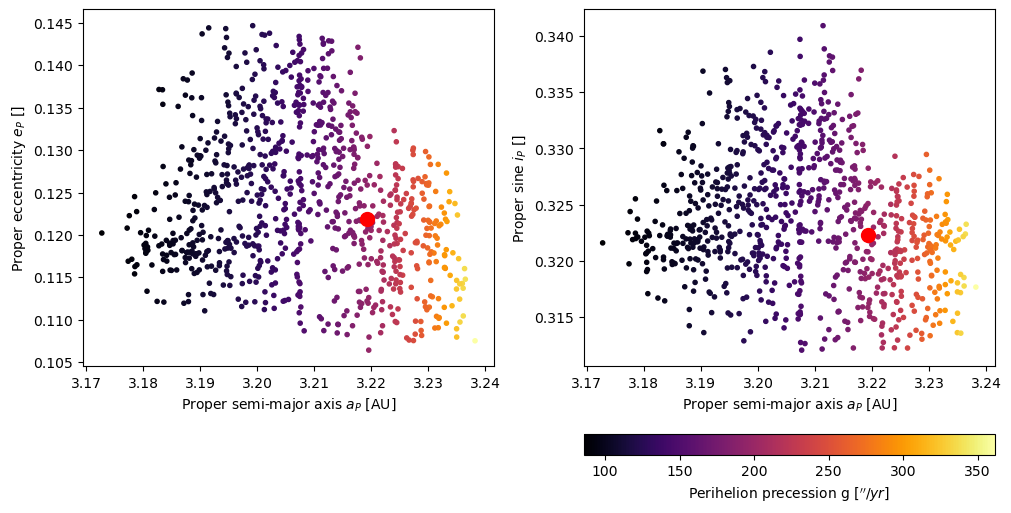

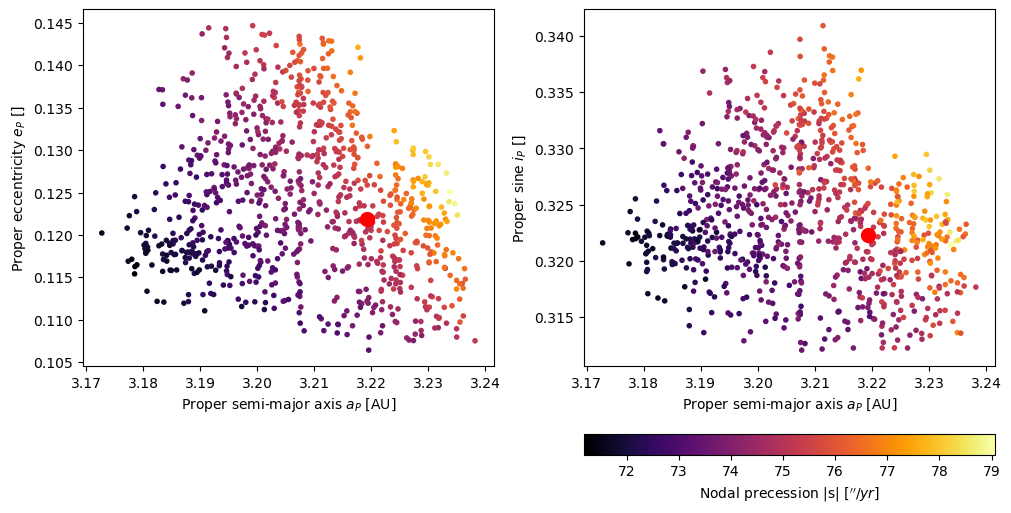

In [16]:
fig = plt.figure(figsize=(10, 5), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])

cm_yr = mpl.colormaps['inferno'] 
colour_values = luth_fam['g']

esc = ax1.scatter(data=luth_fam, x='a_P',y='e_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','e_P']].values
ax1.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper eccentricity $e_P$ []")

ax2 = fig.add_subplot(spec[0, 1])
esc = ax2.scatter(data=luth_fam, x='a_P',y='sineI_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','sineI_P']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper sine $i_P$ []")

fig.colorbar(esc, label="Perihelion precession g [$\'' / yr$]", location='bottom')
plt.savefig(f"../../dissertation/luthera_prp_aei_g.png", dpi=300)
plt.show()

fig = plt.figure(figsize=(10, 5), layout="constrained")
spec = fig.add_gridspec(ncols=2, nrows=1)

ax1 = fig.add_subplot(spec[0, 0])
cm_yr = mpl.colormaps['inferno'] 
colour_values = np.absolute(luth_fam['s'])

esc = ax1.scatter(data=luth_fam, x='a_P',y='e_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','e_P']].values
ax1.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper eccentricity $e_P$ []")

ax2 = fig.add_subplot(spec[0, 1])
esc = ax2.scatter(data=luth_fam, x='a_P',y='sineI_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','sineI_P']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper sine $i_P$ []")

plt.colorbar(esc, label="Nodal precession |s| [$\'' / yr$]", location='bottom')
plt.savefig(f"../../dissertation/luthera_prp_aie_s.png", dpi=300)
plt.show()


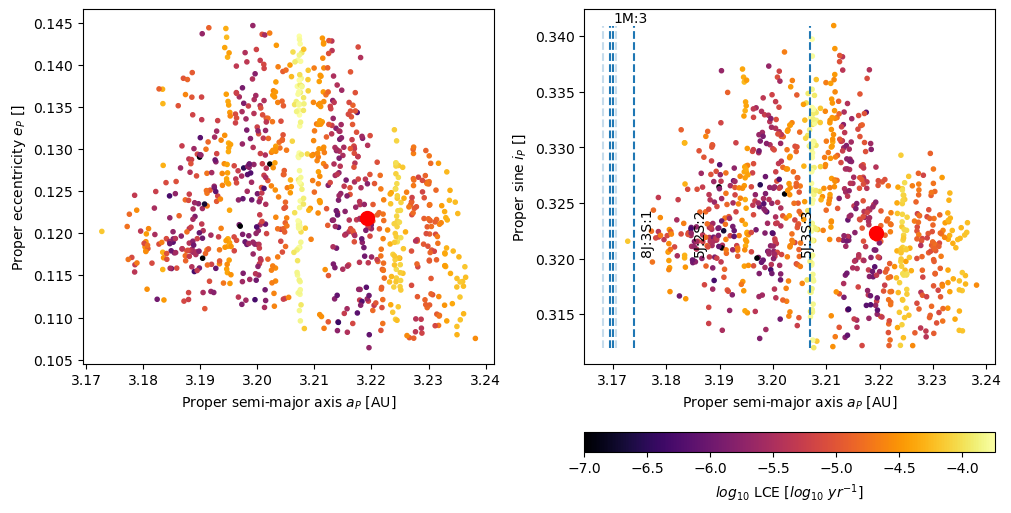

In [17]:
# Get the log(1/lyap_time)
log_lce = np.log10(1/(luth_fam.lyap_time*1e3))

fig = plt.figure(figsize=(10, 5), layout="constrained")
spec = fig.add_gridspec(ncols=2, nrows=1)

ax1 = fig.add_subplot(spec[0, 0])
cm_yr = mpl.colormaps['inferno'] 
colour_values = log_lce

esc = ax1.scatter(data=luth_fam, x='a_P',y='e_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','e_P']].values
ax1.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper eccentricity $e_P$ []")

ax2 = fig.add_subplot(spec[0, 1])
esc = ax2.scatter(data=luth_fam, x='a_P',y='sineI_P', marker=".",c=colour_values, cmap = cm_yr)
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','sineI_P']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper sine $i_P$ []")
plot_mmrs(ax2, sma_range, luth_fam.sineI_P.min(), luth_fam.sineI_P.max())

plt.colorbar(esc, label="$log_{10}$ LCE [$log_{10} ~yr^{-1}$]", location='bottom')
plt.savefig(f"../../dissertation/luthera_prp_aie_lce.png", dpi=300)
plt.show()


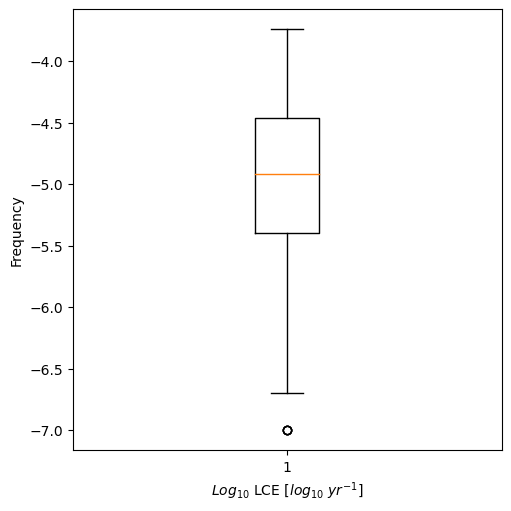

In [19]:
fig = plt.figure(figsize=(5, 5), layout="constrained")

spec = fig.add_gridspec(ncols=1, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])

ax1.boxplot(x=log_lce)
ax1.set_ylabel("Frequency")
ax1.set_xlabel("$Log_{10}$ LCE [$log_{10} ~yr^{-1}$]")
plt.show()

In [20]:
# Estimate the mean motion of a body for a given sma
def n_value(semi_major_axis):
    orbital_p = semi_major_axis**(3/2)
    return (360/orbital_p)

def sma_value(mean_motion):
    orbital_p = 360/mean_motion
    return orbital_p**(2/3)

def nplot_2b_mmr(ax, n_range, y_min, y_max, min_strength=1e-13, y_offset=0.98):
    plt_2b_mmr = mmr_atlas[(mmr_atlas.sma >= sma_value(n_range[1])) & (mmr_atlas.sma <= sma_value(n_range[0])) & 
                            (mmr_atlas.strength > min_strength)]    
    
    for _, mmr in plt_2b_mmr.iterrows():
        label = f"{mmr.ratio1}{mmr.planet[0]}:{mmr.ratio2}"
        if mmr.sma-mmr.width > sma_value(n_range[0]):
            ax.vlines(n_value(mmr.sma-mmr.width), y_min, y_max, linestyles='dashed', alpha=0.25)
        ax.vlines(n_value(mmr.sma), y_min, y_max, linestyles='dashed')
        if mmr.sma+mmr.width < sma_value(n_range[0]):
            ax.vlines(n_value(mmr.sma+mmr.width), y_min, y_max, linestyles='dashed', alpha=0.25)
        ax.text(n_value(mmr.sma), (y_max)*y_offset, label)


def nplot_3b_mmr(ax, n_range, y_min, y_max, y_offset=0.98):
    for mmr_nme, sma in mmrs_3b_luthera.items():
        if n_value(sma[0]) < n_range[0] or n_value(sma[0]) > n_range[1]:
            continue
        ax.vlines(n_value(sma[0]), y_min, y_max, linestyles='dashed')
        ax.text(n_value(sma[1]), y_max * y_offset, mmr_nme,rotation=90)

# add the MMR lines in a plot with an mean motion (n) on x axis.
def nplot_mmrs(ax, n_range, y_min, y_max, y_offset=0.9):
    nplot_2b_mmr(ax, n_range, y_min, y_max)
    nplot_3b_mmr(ax, n_range, y_min, y_max)


# Secular resonances map
sec_res_list = [[saturn_g6, r'$\nu_{6}$'],
           [2*saturn_g6-jupiter_g5, '$g-2g_6+g_5$'], 
           [3*saturn_g6-2*jupiter_g5, '$g-3g_6+2g_5$']]

# Plot the secular resonances


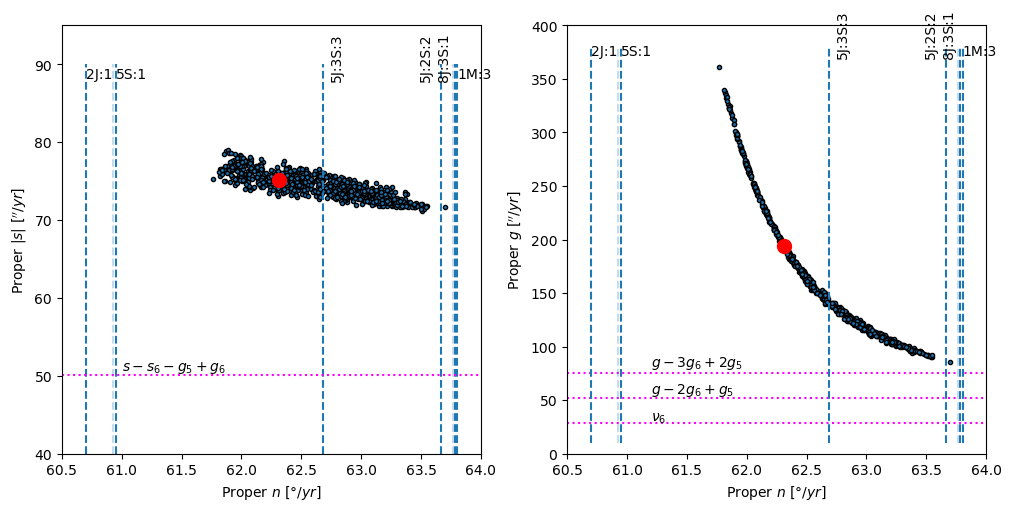

In [29]:
n_range = (60.5,64.0)
fig = plt.figure(figsize=(10, 5), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])

ax1.set_xlim(n_range)
ax1.set_ylim(s_range)

ax1.scatter(x=luth_fam.n,y=np.absolute(luth_fam.s), edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['n','s']].values
ax1.plot(luth_ie[0][0],np.absolute(luth_ie[0][1]), 'ro', markersize=10)
# plot the MMR in n space
nplot_mmrs(ax1, n_range, s_range[0], s_range[1]-5, y_offset=1.1)

# Line was too low at around 40
ax1.hlines(-saturn_s6-jupiter_g5+saturn_g6,60.5,64,linestyles='dotted', colors='magenta')
ax1.text(61.0, 50.7, r'$s-s_6-g_5+g_6$')

ax1.set_xlabel("Proper $n$ [$\degree/yr$]")
ax1.set_ylabel("Proper $|s|$ [$''/yr$]")

ax2 = fig.add_subplot(spec[0, 1])
# spec the x and y axes limits
ax2.set_xlim(n_range)
ax2.set_ylim((0, 400))

ax2.scatter(x=luth_fam.n,y=luth_fam.g, edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['n','g']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper $n$ [$\degree/yr$]")
ax2.set_ylabel("Proper $g$ [$''/yr$]")

# Plot the secular resonances
for sec_res in sec_res_list: 
    ax2.hlines(sec_res[0], n_range[0], n_range[1], linestyles='dotted', color='magenta')
    ax2.text(61.2, sec_res[0]*1.08,  sec_res[1])


# plot the MMR in n space
nplot_mmrs(ax2, n_range, 10, 380, y_offset=1.04)

plt.savefig(f"../../dissertation/luthera_prp_ng.png", dpi=300)
plt.show()

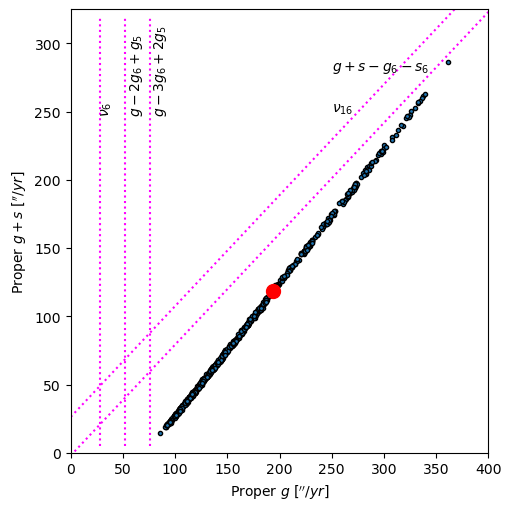

In [31]:
s_range = (40, 95)
fig, ax1 = plt.subplots(figsize=(5, 5), layout="constrained")

# spec the x and y axes limits
g_range = (0, 400)
gs_range = (0, 325)
ax1.set_xlim(g_range)
ax1.set_ylim(gs_range)
g_s = luth_fam.g+luth_fam.s
ax1.scatter(x=luth_fam.g,y=g_s, edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['g','s']].values
ax1.plot(luth_ie[0][0],luth_ie[0][0]+luth_ie[0][1], 'ro', markersize=10)

# v_6 
ax1.vlines(sec_res_list[0][0], 5, 320, linestyles='dotted', colors='magenta')
ax1.text(28, 250, sec_res_list[0][1],rotation=90)
# g-2g_6+g_5
ax1.vlines(sec_res_list[1][0], 5, 320, linestyles='dotted', colors='magenta')
ax1.text(55, 250, sec_res_list[1][1],rotation=90)
# g-3g_6+2g_5
ax1.vlines(sec_res_list[2][0], 5, 320, linestyles='dotted', colors='magenta')
ax1.text(78, 250, sec_res_list[2][1],rotation=90)
# s-s_6
g_vals = np.linspace(g_range[0],g_range[1], 100)
gs_vals = np.linspace(gs_range[0],gs_range[1], 100)
ax1.plot(g_vals, gs_vals-saturn_s6, ls='dotted', c='magenta')
ax1.text(250, 250, r'$\nu_{16}$')
# s-s_6-g_5+g_6
g_vals = np.linspace(g_range[0],g_range[1], 100)
gs_vals = np.linspace(gs_range[0],gs_range[1], 100)
ax1.plot(g_vals, gs_vals-saturn_g6-saturn_s6, ls='dotted', c='magenta')
ax1.text(250, 280, r'$g + s - g_6 - s_6$')

ax1.set_xlabel("Proper $g$ [$''/yr$]")
ax1.set_ylabel("Proper $g+s$ [$''/yr$]")


plt.savefig(f"../../dissertation/luthera_prp_ggs.png", dpi=300)
plt.show()

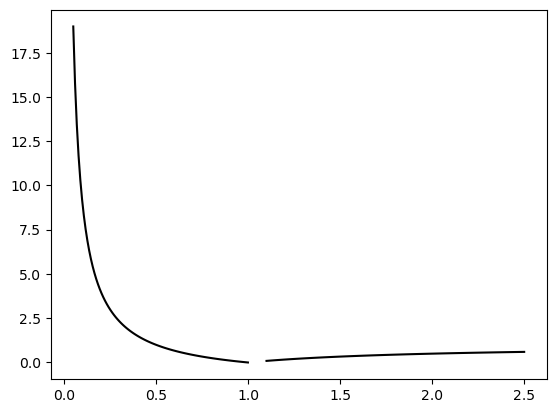

In [21]:

## From Tim
#---Apehilion and Perihelion lines

limit = 2.5
##q - perihelion
xsmau = np.linspace(1.1 , limit, 100)
ysmau = 0.9833 -(1/xsmau)
plt.plot(xsmau, ysmau, color = 'black')

##Q - aphelion
xsmal = np.linspace(0.05, 0.999, 100)
ysmal =  (1/xsmal) - 1.0167
plt.plot(xsmal, ysmal, color = 'black')
plt.show()

In [22]:
def calc_crossing_e_sp(sma, ecc, p_limit, a_limit):
    sma_p, sma_a = get_ap_pe(sma, ecc) 
    
    # Perihelion - q ?
    sma_range = np.linspace(sma_a, a_limit, 10)
    p_ecc =  sma_p - (1/sma_range) 
    p_vals = np.vstack([sma_range, p_ecc])
    
    # Aphelion - Q?
    sma_range = np.linspace(p_limit, sma_p, 10)
    a_ecc = (1/sma_range) - sma_a
    a_vals = np.vstack([sma_range, a_ecc])
        
    return a_vals, p_vals 

In [23]:
p_vals, a_vals = calc_crossing_e_sp(e_ax,e_ecc,0.1, 2.5)
print(list(p_vals),'\n')
print(list(a_vals),'\n')

[array([0.1 , 0.2 , 0.3 , 0.39, 0.49, 0.59, 0.69, 0.79, 0.89, 0.98]), array([8.98e+00, 4.03e+00, 2.36e+00, 1.52e+00, 1.01e+00, 6.76e-01,
       4.35e-01, 2.54e-01, 1.13e-01, 2.84e-04])] 

[array([1.02, 1.18, 1.35, 1.51, 1.68, 1.84, 2.01, 2.17, 2.34, 2.5 ]), array([-2.74e-04,  1.37e-01,  2.41e-01,  3.22e-01,  3.87e-01,  4.40e-01,
        4.85e-01,  5.23e-01,  5.55e-01,  5.83e-01])] 



In [24]:
ap, pe = get_ap_pe(j_ax, j_e)
print(f'Jupiter parameters semimajor axis:{j_ax:0.4f}, eccentricity:{j_e:0.4f}, perihelion:{pe:0.4f}, aphelion:{ap:0.4f}')

ap, pe = get_ap_pe(j21_ax, j_e)
print(f'MMR 2J:1 parameters semimajor axis:{j21_ax}, eccentricity:{j_e}, perihelion:{pe}, aphelion:{ap}\n')

p_vals, a_vals = calc_crossing_e_sp(j21_ax,j_e,1.8, 3.7)
print(list(p_vals),'\n')
print(list(a_vals),'\n')


NameError: name 'j_ax' is not defined

In [ ]:
pe_vals, ap_vals = calc_crossing_e(e_ax, e_ecc, 0.1, 1.5)
print('\nBCW Attempt\n', pe_vals[0], '\n', pe_vals[1])
print(ap_vals[0], '\n', ap_vals[1])

In [ ]:
pe_vals, ap_vals = calc_crossing_e_sp(e_ax, e_ecc, 0.1, 1.5)
print('Supplied\n', pe_vals[0], '\n', pe_vals[1])
print(ap_vals[0], '\n', ap_vals[1])

In [ ]:
print('1.0 = 0.1*(1.0+e)')
print((1.0/0.1)-1)
